# HPLT label distributions by data quality and language

**Questions:**

1. How do the topic and format label distributions differ between the HPLT 4.0
   collections: clean, noisy and poor?
2. Which languages have a clearly different distribution from the other languages of the
   same collection, and why?

**Data:** the Qwen3.8-27B label distributions of the random HPLT samples, made by
`hpc/lumi/array_generate_distribution_hplt.sh`:
`results/distribution/Qwen3.8-27B-hplt-annotations/<quality>/<label type>/<language>.jsonl`,
where `<quality>` is `clean_random`, `noisy_random` or `poor_random`.

**Method in short:**

- From each result file, the notebook reads the first `N_DOCS` documents (3,000 by default).
  The samples were shuffled before labelling and the labelling run follows the sample
  order, so the first documents of a file are a random subset of the language's sample.
- A label's **share** in a language is its mean probability over those documents (its
  share of the soft labels). The **top share** is the share of documents whose most
  probable label it is. The two are almost equal where the model is confident.
- A collection's distribution is the **mean over its languages**: every language counts
  equally, whatever its size.
- A language **stands out** when its distribution is far from the mean of the languages
  of the same collection and label type (Jensen-Shannon divergence; see section 4).

The notebook only reads the result files; it writes nothing but a cache of the summaries
(see *Parameters*). It runs on LUMI or on a machine with the project directory mounted;
over a mount, the first run reads about 10 GB and takes around 20 minutes.

## Setup

Imports, the repository root, and the chart style.

- **Repository root:** found from the current directory, so the notebook works whether
  Jupyter was started in the repository root or in `notebooks/`.
- **Packages:** the standard library plus `numpy`, `pandas`, `matplotlib` and `yaml`
  (for the label files).
- **Chart colours:** one fixed colour per collection, used in every chart: clean blue,
  noisy orange, poor green. These are the first three colours of a palette
  checked for colour-blind readers. Deviations use a blue-grey-red scale with grey
  meaning "same as the average".
- **`annotate_without_overlap`** names points in charts without names covering each
  other or other points; a name that doesn't fit is left out (the tables list everything).

In [44]:
from __future__ import annotations

import json
import math
import warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Any
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.colors import LinearSegmentedColormap

# Find the repository root whether Jupyter runs from the root or from notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 120)

# One colour per collection, the same in every chart.
QUALITY_COLORS = {"clean_random": "#06d63e", "noisy_random": "#e3cb13", "poor_random": "#e82507"}
SURFACE, TEXT, MUTED, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#b5b4ae"
# Diverging scale for deviations: blue (below average), grey (average), red (above).
DIVERGING = LinearSegmentedColormap.from_list("deviation", ["#256abf", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
    "legend.frameon": False,
})


def annotate_without_overlap(ax: plt.Axes, points: list[tuple[float, float, str]], fontsize: int = 8) -> None:
    # Name points in order of importance, each beside its point where the name overlaps
    # no other name or marker; a name with no free place is left out.
    fig = ax.figure
    fig.canvas.draw()
    to_pixels = fig.dpi / 72
    char_width, height = 0.6 * fontsize * to_pixels, 1.2 * fontsize * to_pixels
    frame = ax.get_window_extent()
    taken = []
    for collection in ax.collections:  # every scatter marker, as a small box
        for x, y in ax.transData.transform(collection.get_offsets()):
            taken.append((x - 4, y - 4, x + 4, y + 4))
    for x, y, text in points:
        px, py = ax.transData.transform((x, y))
        width = char_width * len(text)
        for dx, dy in ((6, 3), (6, -3 - height), (-6 - width, 3), (-6 - width, -3 - height)):
            box = (px + dx, py + dy, px + dx + width, py + dy + height)
            inside = frame.x0 <= box[0] and box[2] <= frame.x1 and frame.y0 <= box[1] and box[3] <= frame.y1
            clear = not any(box[0] < b[2] and b[0] < box[2] and box[1] < b[3] and b[1] < box[3]
                            for b in taken if not (b[0] < px < b[2] and b[1] < py < b[3]))
            if inside and clear:
                taken.append(box)
                ax.annotate(text, (x, y), xytext=(dx / to_pixels, dy / to_pixels), textcoords="offset points",
                            fontsize=fontsize, color=TEXT, va="bottom")
                break


print("Repository root:", ROOT)

Repository root: /home/otto-tarkka/mnt/lumi-1516/MultilingualWebOrganizer


## Parameters

Everything a typical rerun changes is set here.

- `N_DOCS`: documents read from the start of each result file. 3,000 gives a standard
  error of at most about 1 percentage point for a label's share in one language, and
  reproduces the analysis of 5 November 2026. `None` reads every document (much slower).
- `ANNOTATIONS`: the labelling results.
- `QUALITIES`, `LABEL_TYPES`: what to compare. A collection or label type without
  results yet is skipped, so the notebook can be rerun while labelling is in progress.
- `CACHE_PATH`: summaries of the files already read. A rerun reads only new files and
  files that had fewer than `N_DOCS` documents last time (results are only appended, so
  a file's first `N_DOCS` documents never change once written). Set `REFRESH = True` to
  read every file again, for example after a result file was replaced.
- `WORKERS`: files read in parallel. Reading is limited by the file system, not the CPU.
- `OUTLIER_MAD`: how far from the typical language a language must be to be flagged
  (see section 4).

In [65]:
N_DOCS: int | None = 3000
ANNOTATIONS = ROOT / "results/distribution/Qwen3.8-27B-hplt-annotations"
QUALITIES = ("clean_random", "noisy_random", "poor_random")
LABEL_TYPES = ("topic", "format")
LABEL_FILES = {label_type: ROOT / f"scripts/data_processing/{label_type}s.yaml" for label_type in LABEL_TYPES}
CACHE_PATH = ROOT / "results/analysis/hplt_label_distribution_summary.json"
FIGURE_PATH = ROOT / "figures"
REFRESH = False
WORKERS = 16
OUTLIER_MAD = 4.0

## 1. Read the result files

### Label names

The label files define each label's short name (the key in the results' `label_probs`)
and its full name, and the order used in every table below.

In [46]:
def load_labels(path: Path) -> dict[str, str]:
    # Short name -> full name, in label-file order.
    raw = yaml.safe_load(path.read_text(encoding="utf-8"))
    if not isinstance(raw, list) or not raw:
        raise ValueError(f"Expected a list of labels in {path}")
    return {str(item["short_name"]): str(item["name"]) for item in raw}


LABELS = {label_type: load_labels(path) for label_type, path in LABEL_FILES.items()}
for label_type, labels in LABELS.items():
    print(f"{label_type}: {len(labels)} labels")

topic: 26 labels
format: 26 labels


### Summarize one file

`summarize_file` reads the first `N_DOCS` records of one result file and keeps only what
the analysis needs:

- the summed probability and the top-label count of every label;
- the median text length in characters;
- the number of documents per website domain (the 20 most common, and how many distinct
  domains there are), to see whether a few websites dominate a language;
- for every top label, the first document that has it, as an example.

It fails loudly on a record whose labels don't match the label file. A run that is still
writing a file can leave a partial last line; that line is not used, with a warning.

In [47]:
def summarize_file(path: Path, n_docs: int | None, labels: dict[str, str]) -> dict[str, Any]:
    names = list(labels)
    soft = dict.fromkeys(names, 0.0)
    top: Counter[str] = Counter()
    domains: Counter[str] = Counter()
    lengths: list[int] = []
    examples: dict[str, dict[str, Any]] = {}
    without_url = 0
    with path.open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            if n_docs is not None and len(lengths) >= n_docs:
                break
            if not line.endswith("\n"):
                warnings.warn(f"{path}:{line_number} has no line end (is the run still writing?); not used")
                break
            record = json.loads(line)
            probs = record["label_probs"]
            if set(probs) != set(names):
                raise ValueError(f"{path}:{line_number}: the labels don't match {LABEL_FILES}")
            for name in names:
                soft[name] += probs[name]
            best = max(names, key=lambda name: probs[name])  # the first in label order on a tie
            top[best] += 1
            text = record["text"]
            lengths.append(len(text))
            url = record.get("url")
            if url:
                domains[urlsplit(url).netloc.lower().removeprefix("www.")] += 1
            else:
                without_url += 1
            examples.setdefault(best, {"id": record["id"], "url": url, "text": text[:400]})
    lengths.sort()
    return {
        "n": len(lengths),
        "soft": soft,
        "top": dict(top),
        "median_chars": lengths[len(lengths) // 2] if lengths else None,
        "distinct_domains": len(domains),
        "without_url": without_url,
        "top_domains": domains.most_common(20),
        "examples": examples,
    }

### Read every file, reusing the cache

This cell finds the result files, decides which ones need reading (see `CACHE_PATH`
under *Parameters*), reads them in parallel, and saves the cache. It prints how many
files it read and how many it took from the cache.

In [48]:
def relative(path: Path) -> str:
    return str(path.relative_to(ANNOTATIONS))


files = [
    path
    for quality in QUALITIES
    for label_type in LABEL_TYPES
    for path in sorted((ANNOTATIONS / quality / label_type).glob("*.jsonl"))
]
cache: dict[str, Any] = {}
if CACHE_PATH.exists() and not REFRESH:
    cache = json.loads(CACHE_PATH.read_text(encoding="utf-8"))
if cache.get("n_docs") != N_DOCS:
    cache = {"n_docs": N_DOCS, "files": {}}
# Forget files that are gone, e.g. after a result directory was moved.
cache["files"] = {key: value for key, value in cache["files"].items() if (ANNOTATIONS / key).exists()}


def needs_reading(path: Path) -> bool:
    cached = cache["files"].get(relative(path))
    if cached is None:
        return True
    # A file with all N_DOCS documents can't change them: results are only appended.
    full = N_DOCS is not None and cached["n"] >= N_DOCS
    return not full and cached["size"] != path.stat().st_size


todo = [path for path in files if needs_reading(path)]
print(f"{len(files)} result files; reading {len(todo)}, {len(files) - len(todo)} from the cache")


def read_one(path: Path) -> tuple[str, dict[str, Any]]:
    label_type = path.parent.name
    summary = summarize_file(path, N_DOCS, LABELS[label_type])
    summary["size"] = path.stat().st_size
    return relative(path), summary


with ThreadPoolExecutor(max_workers=WORKERS) as pool:
    for done, (key, summary) in enumerate(pool.map(read_one, todo), start=1):
        cache["files"][key] = summary
        if done % 50 == 0 or done == len(todo):
            print(f"  read {done}/{len(todo)}")

CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
CACHE_PATH.write_text(json.dumps(cache, ensure_ascii=False), encoding="utf-8")
print("Cache saved to", CACHE_PATH)

768 result files; reading 0, 768 from the cache
Cache saved to /home/otto-tarkka/mnt/lumi-1516/MultilingualWebOrganizer/results/analysis/hplt_label_distribution_summary.json


### Tables to work with

Two tables are built from the summaries:

- `files_df`: one row per result file (collection, label type, language), with the
  documents read, the median text length, and how concentrated the domains are:
  `top_domain_share` is the share of the documents that come from the most common
  domain, and `top5_domain_share` from the five most common together.
- `shares`: one row per file and label, with the label's `share` (mean probability) and
  `top_share` (share of documents with it as the top label), both in percent.

Files with no documents (a run that has only just started) are left out, and listed.

In [49]:
file_rows, share_rows = [], []
for key, summary in cache["files"].items():
    quality, label_type, file_name = Path(key).parts
    language = Path(file_name).stem
    n = summary["n"]
    if n == 0:
        print("No documents yet:", key)
        continue
    top_domain, top_count = summary["top_domains"][0] if summary["top_domains"] else (None, 0)
    file_rows.append({
        "quality": quality, "label_type": label_type, "language": language, "n": n,
        "median_chars": summary["median_chars"], "distinct_domains": summary["distinct_domains"],
        "top_domain": top_domain, "top_domain_share": 100 * top_count / n,
        "top5_domain_share": 100 * sum(count for _, count in summary["top_domains"][:5]) / n,
    })
    for label, full_name in LABELS[label_type].items():
        share_rows.append({
            "quality": quality, "label_type": label_type, "language": language, "label": full_name,
            "share": 100 * summary["soft"][label] / n,
            "top_share": 100 * summary["top"].get(label, 0) / n,
        })
files_df = pd.DataFrame(file_rows)
shares = pd.DataFrame(share_rows)
LABEL_ORDER = {label_type: list(labels.values()) for label_type, labels in LABELS.items()}
files_df.head()

,quality,label_type,language,n,median_chars,distinct_domains,top_domain,top_domain_share,top5_domain_share
0,clean_random,topic,afrikaans,3000,2194,1386,maroelamedia.co.za,6.100000,13.733333
1,clean_random,topic,albanian,3000,1358,1241,sq.airbnb.com,1.800000,6.400000
2,clean_random,topic,amharic,3000,1616,1158,addisadmassnews.com,3.766667,14.433333
3,clean_random,topic,arabic,3000,1819,2507,alwasatnews.com,0.633333,2.233333
4,clean_random,topic,armenian,3000,1485,1078,armtimes.com,2.933333,10.033333


## 2. Coverage

How many languages and documents each collection and label type has so far. Labelling
may still be running, so check this before reading the comparisons: a collection with
few languages is compared on those languages only. The second table lists the files with
fewer than `N_DOCS` documents (small languages, or runs still in progress).

In [50]:
coverage = files_df.groupby(["label_type", "quality"]).agg(languages=("language", "nunique"), documents=("n", "sum"))
display(coverage.unstack("label_type"))

if N_DOCS is not None:
    short = files_df[files_df["n"] < N_DOCS].sort_values(["label_type", "quality", "n"])
    print(f"{len(short)} files with fewer than {N_DOCS} documents:")
    display(short[["label_type", "quality", "language", "n"]].reset_index(drop=True))

languages       documents        
label_type      format topic    format   topic
quality                                       
clean_random       128   128    379724  379724
noisy_random       128   128    381721  381721
poor_random        128   128    384000  384000

8 files with fewer than 3000 documents:


,label_type,quality,language,n
0,format,clean_random,magahi,524
1,format,clean_random,banjar_arabic,1200
2,format,noisy_random,magahi,959
3,format,noisy_random,banjar_arabic,2762
4,topic,clean_random,magahi,524
5,topic,clean_random,banjar_arabic,1200
6,topic,noisy_random,magahi,959
7,topic,noisy_random,banjar_arabic,2762


## 3. Label distributions by data quality

`quality_table` averages the label shares over the languages of each collection, so every
language counts equally. With `languages` given, it uses only those languages: this
matters while one collection has fewer languages than the others, since a different mix
of languages could look like a difference between collections. The comparison is
therefore shown twice: on all languages each collection has, and on the languages all
of them have.

In the tables, `share` is the mean probability and `top_share` the share of documents
with the label as their top label, both in percent.

In [51]:
def quality_table(label_type: str, languages: set[str] | None = None) -> pd.DataFrame:
    data = shares[shares["label_type"] == label_type]
    if languages is not None:
        data = data[data["language"].isin(languages)]
    table = data.groupby(["label", "quality"])[["share", "top_share"]].mean().unstack("quality")
    present = [quality for quality in QUALITIES if quality in table["share"].columns]
    table = table.reindex(columns=pd.MultiIndex.from_product([["share", "top_share"], present]))
    return table.reindex(LABEL_ORDER[label_type])


def common_languages(label_type: str) -> set[str]:
    data = files_df[files_df["label_type"] == label_type]
    per_quality = [set(group["language"]) for _, group in data.groupby("quality")]
    return set.intersection(*per_quality) if per_quality else set()

### Chart: label shares per collection

`plot_quality_shares` draws one row per label with a dot per collection, joined by a grey
line, so both the size of a label and how much it moves between collections are visible.
Labels are sorted by their largest share. The chart uses all languages each collection
has; the table under it gives the exact numbers.

In [66]:
def plot_quality_shares(table: pd.DataFrame, label_type: str, title_note: str) -> None:
    share = table["share"]
    order = share.max(axis=1).sort_values().index
    fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(order) + 1.4))
    y = np.arange(len(order))
    ax.hlines(y, share.loc[order].min(axis=1), share.loc[order].max(axis=1), color=NEUTRAL, linewidth=2, zorder=1)
    for quality in share.columns:
        ax.scatter(share.loc[order, quality], y, s=42, color=QUALITY_COLORS[quality], label=quality.removesuffix("_random"),
                   edgecolor=SURFACE, linewidth=1.5, zorder=2)
    ax.set_yticks(y, order)
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)
    ax.set_xlabel("Share of documents, % (mean label probability)")
    ax.set_title(f"{label_type.capitalize()} labels by data quality {title_note}", loc="left")
    ax.legend(loc="lower right", ncols=len(share.columns), handletextpad=0.2)
    plt.tight_layout()
    plt.savefig(FIGURE_PATH / f"{label_type}_label_shares.png", dpi=300)
    plt.show()

### Topic

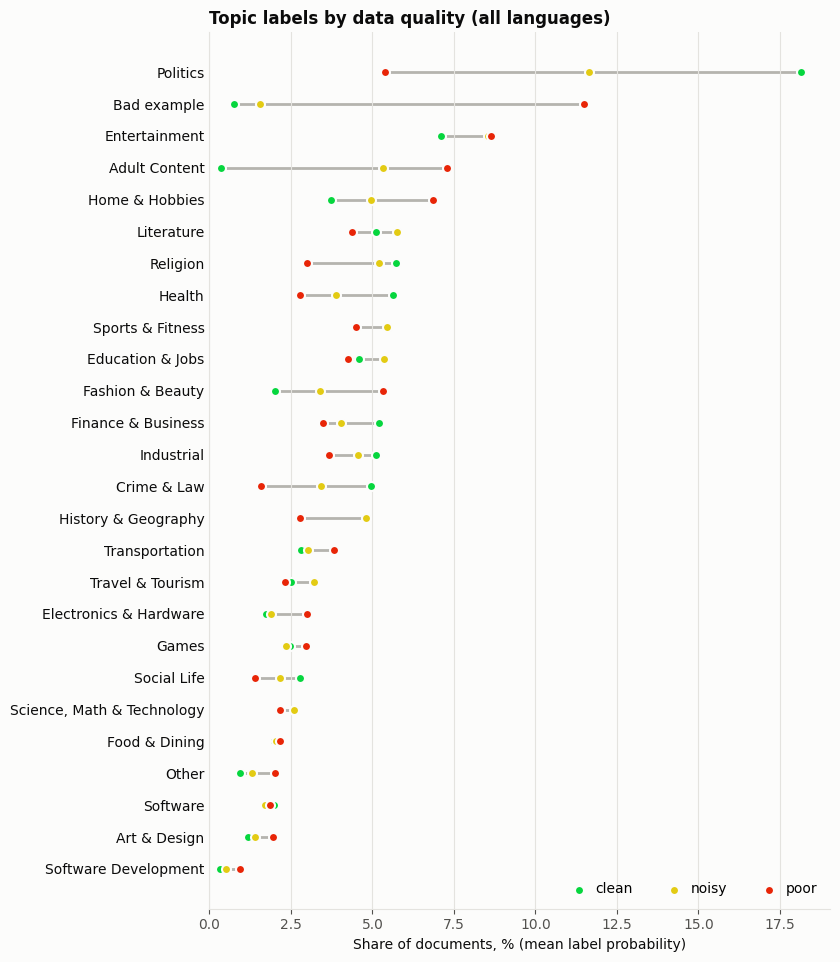

share                             top_share  \
                           clean_random noisy_random poor_random clean_random   
label                                                                           
Adult Content                       0.4          5.3         7.3          0.4   
Art & Design                        1.2          1.4         1.9          1.2   
Software Development                0.3          0.5         0.9          0.3   
Crime & Law                         5.0          3.4         1.6          5.0   
Education & Jobs                    4.6          5.3         4.2          4.7   
Electronics & Hardware              1.7          1.9         3.0          1.7   
Entertainment                       7.1          8.6         8.6          7.2   
Social Life                         2.8          2.2         1.4          2.8   
Fashion & Beauty                    2.0          3.4         5.3          2.0   
Finance & Business                  5.2          4.0         3.5          5.1   
Food & Dining                       2.0          2.0         2.2          2.0   
Games                               2.5          2.3         3.0          2.5   
Health                              5.6          3.9         2.8          5.7   
History & Geography                 4.8          4.8         2.8          4.7   
Home & Hobbies                      3.7          4.9         6.9          3.7   
Industrial                          5.1          4.6         3.7          5.2   
Literature                          5.1          5.7         4.4          5.3   
Politics                           18.1         11.6         5.4         18.3   
Religion                            5.7          5.2         3.0          5.8   
Science, Math & Technology          2.6          2.6         2.2          2.6   
Software                            2.0          1.7         1.8          2.0   
Sports & Fitness                    5.5          5.4         4.5          5.5   
Transportation                      2.8          3.0         3.8          2.8   
Travel & Tourism                    2.5          3.2         2.3          2.5   
Other                               0.9          1.3         2.0          0.6   
Bad example                         0.8          1.6        11.5          0.6   

                                                     
                           noisy_random poor_random  
label                                                
Adult Content                       5.3         7.3  
Art & Design                        1.4         2.0  
Software Development                0.5         0.9  
Crime & Law                         3.4         1.6  
Education & Jobs                    5.4         4.4  
Electronics & Hardware              1.9         3.0  
Entertainment                       8.6         8.8  
Social Life                         2.2         1.4  
Fashion & Beauty                    3.4         5.4  
Finance & Business                  4.0         3.5  
Food & Dining                       2.0         2.2  
Games                               2.4         3.0  
Health                              3.9         2.9  
History & Geography                 4.8         2.8  
Home & Hobbies                      5.0         7.1  
Industrial                          4.6         3.7  
Literature                          5.9         4.6  
Politics                           11.8         5.5  
Religion                            5.2         3.0  
Science, Math & Technology          2.6         2.1  
Software                            1.7         1.8  
Sports & Fitness                    5.5         4.6  
Transportation                      3.0         3.9  
Travel & Tourism                    3.2         2.3  
Other                               0.8         1.2  
Bad example                         1.2        10.9

In [67]:
topic_all = quality_table("topic")
plot_quality_shares(topic_all, "topic", "(all languages)")
display(topic_all.round(1))

The same comparison on the languages that every collection has, to check that a
difference isn't just a different set of languages:

In [68]:
topic_common = common_languages("topic")
print(f"{len(topic_common)} languages in every collection")
display(quality_table("topic", topic_common).round(1))

128 languages in every collection


share                             top_share  \
                           clean_random noisy_random poor_random clean_random   
label                                                                           
Adult Content                       0.4          5.3         7.3          0.4   
Art & Design                        1.2          1.4         1.9          1.2   
Software Development                0.3          0.5         0.9          0.3   
Crime & Law                         5.0          3.4         1.6          5.0   
Education & Jobs                    4.6          5.3         4.2          4.7   
Electronics & Hardware              1.7          1.9         3.0          1.7   
Entertainment                       7.1          8.6         8.6          7.2   
Social Life                         2.8          2.2         1.4          2.8   
Fashion & Beauty                    2.0          3.4         5.3          2.0   
Finance & Business                  5.2          4.0         3.5          5.1   
Food & Dining                       2.0          2.0         2.2          2.0   
Games                               2.5          2.3         3.0          2.5   
Health                              5.6          3.9         2.8          5.7   
History & Geography                 4.8          4.8         2.8          4.7   
Home & Hobbies                      3.7          4.9         6.9          3.7   
Industrial                          5.1          4.6         3.7          5.2   
Literature                          5.1          5.7         4.4          5.3   
Politics                           18.1         11.6         5.4         18.3   
Religion                            5.7          5.2         3.0          5.8   
Science, Math & Technology          2.6          2.6         2.2          2.6   
Software                            2.0          1.7         1.8          2.0   
Sports & Fitness                    5.5          5.4         4.5          5.5   
Transportation                      2.8          3.0         3.8          2.8   
Travel & Tourism                    2.5          3.2         2.3          2.5   
Other                               0.9          1.3         2.0          0.6   
Bad example                         0.8          1.6        11.5          0.6   

                                                     
                           noisy_random poor_random  
label                                                
Adult Content                       5.3         7.3  
Art & Design                        1.4         2.0  
Software Development                0.5         0.9  
Crime & Law                         3.4         1.6  
Education & Jobs                    5.4         4.4  
Electronics & Hardware              1.9         3.0  
Entertainment                       8.6         8.8  
Social Life                         2.2         1.4  
Fashion & Beauty                    3.4         5.4  
Finance & Business                  4.0         3.5  
Food & Dining                       2.0         2.2  
Games                               2.4         3.0  
Health                              3.9         2.9  
History & Geography                 4.8         2.8  
Home & Hobbies                      5.0         7.1  
Industrial                          4.6         3.7  
Literature                          5.9         4.6  
Politics                           11.8         5.5  
Religion                            5.2         3.0  
Science, Math & Technology          2.6         2.1  
Software                            1.7         1.8  
Sports & Fitness                    5.5         4.6  
Transportation                      3.0         3.9  
Travel & Tourism                    3.2         2.3  
Other                               0.8         1.2  
Bad example                         1.2        10.9

### Format

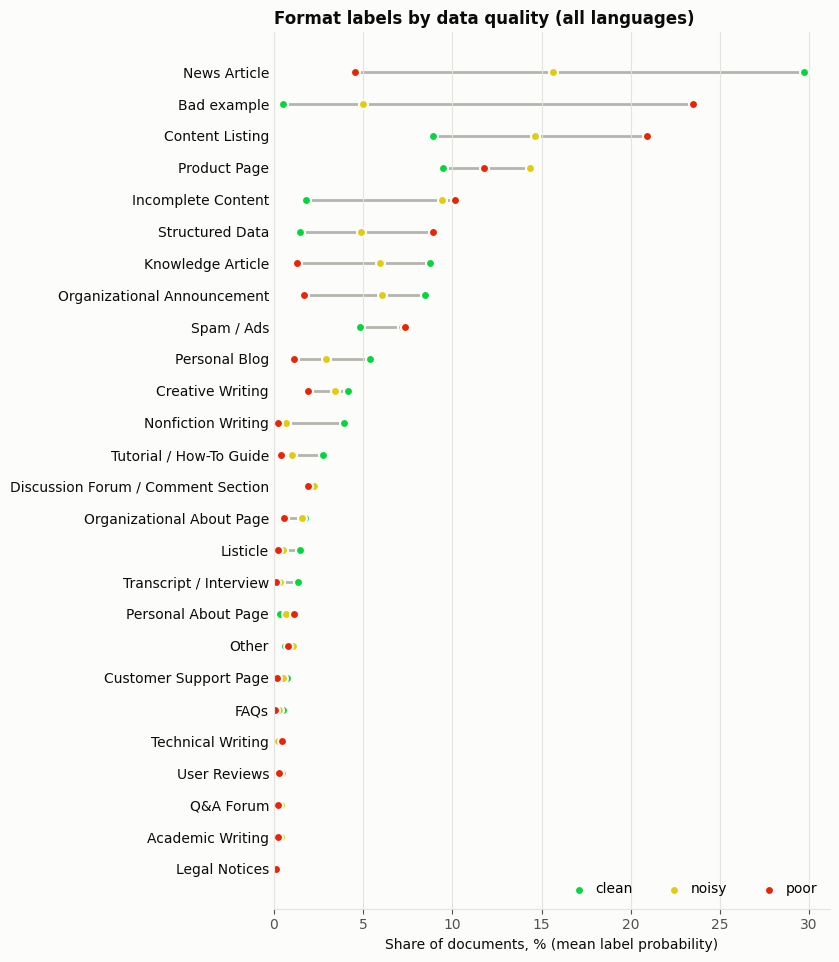

share                           \
                                   clean_random noisy_random poor_random   
label                                                                      
Academic Writing                            0.3          0.4         0.2   
Content Listing                             8.9         14.7        20.9   
Creative Writing                            4.2          3.4         1.9   
Customer Support Page                       0.7          0.5         0.2   
Discussion Forum / Comment Section          1.9          2.2         1.9   
FAQs                                        0.5          0.3         0.1   
Incomplete Content                          1.8          9.4        10.1   
Knowledge Article                           8.7          6.0         1.3   
Legal Notices                               0.4          0.2         0.1   
Listicle                                    1.4          0.5         0.2   
News Article                               29.7         15.6         4.5   
Nonfiction Writing                          3.9          0.7         0.2   
Organizational About Page                   1.7          1.6         0.6   
Organizational Announcement                 8.5          6.1         1.7   
Personal About Page                         0.3          0.7         1.1   
Personal Blog                               5.4          2.9         1.1   
Product Page                                9.5         14.3        11.8   
Q&A Forum                                   0.2          0.4         0.2   
Spam / Ads                                  4.8          7.2         7.4   
Structured Data                             1.4          4.9         8.9   
Technical Writing                           0.1          0.2         0.5   
Transcript / Interview                      1.4          0.4         0.1   
Tutorial / How-To Guide                     2.7          1.0         0.4   
User Reviews                                0.3          0.4         0.3   
Other                                       0.6          1.1         0.8   
Bad example                                 0.5          5.0        23.5   

                                      top_share                           
                                   clean_random noisy_random poor_random  
label                                                                     
Academic Writing                            0.3          0.4         0.2  
Content Listing                             9.0         15.4        21.7  
Creative Writing                            4.3          3.5         1.9  
Customer Support Page                       0.7          0.5         0.2  
Discussion Forum / Comment Section          1.9          2.4         1.9  
FAQs                                        0.5          0.3         0.1  
Incomplete Content                          1.5          9.1         8.6  
Knowledge Article                           8.6          5.7         1.1  
Legal Notices                               0.4          0.2         0.1  
Listicle                                    1.4          0.4         0.2  
News Article                               30.7         16.2         4.5  
Nonfiction Writing                          3.9          0.6         0.2  
Organizational About Page                   1.7          1.7         0.6  
Organizational Announcement                 8.2          6.1         1.6  
Personal About Page                         0.3          0.7         1.1  
Personal Blog                               5.3          2.9         1.0  
Product Page                                9.7         14.7        12.4  
Q&A Forum                                   0.2          0.4         0.2  
Spam / Ads                                  4.8          6.9         7.1  
Structured Data                             1.3          4.9         8.6  
Technical Writing                           0.1          0.2         0.4  
Transcript / Interview               

In [69]:
format_all = quality_table("format")
plot_quality_shares(format_all, "format", "(all languages)")
display(format_all.round(1))

In [56]:
format_common = common_languages("format")
print(f"{len(format_common)} languages in every collection")
display(quality_table("format", format_common).round(1))

128 languages in every collection


share                           \
                                   clean_random noisy_random poor_random   
label                                                                      
Academic Writing                            0.3          0.4         0.2   
Content Listing                             8.9         14.7        20.9   
Creative Writing                            4.2          3.4         1.9   
Customer Support Page                       0.7          0.5         0.2   
Discussion Forum / Comment Section          1.9          2.2         1.9   
FAQs                                        0.5          0.3         0.1   
Incomplete Content                          1.8          9.4        10.1   
Knowledge Article                           8.7          6.0         1.3   
Legal Notices                               0.4          0.2         0.1   
Listicle                                    1.4          0.5         0.2   
News Article                               29.7         15.6         4.5   
Nonfiction Writing                          3.9          0.7         0.2   
Organizational About Page                   1.7          1.6         0.6   
Organizational Announcement                 8.5          6.1         1.7   
Personal About Page                         0.3          0.7         1.1   
Personal Blog                               5.4          2.9         1.1   
Product Page                                9.5         14.3        11.8   
Q&A Forum                                   0.2          0.4         0.2   
Spam / Ads                                  4.8          7.2         7.4   
Structured Data                             1.4          4.9         8.9   
Technical Writing                           0.1          0.2         0.5   
Transcript / Interview                      1.4          0.4         0.1   
Tutorial / How-To Guide                     2.7          1.0         0.4   
User Reviews                                0.3          0.4         0.3   
Other                                       0.6          1.1         0.8   
Bad example                                 0.5          5.0        23.5   

                                      top_share                           
                                   clean_random noisy_random poor_random  
label                                                                     
Academic Writing                            0.3          0.4         0.2  
Content Listing                             9.0         15.4        21.7  
Creative Writing                            4.3          3.5         1.9  
Customer Support Page                       0.7          0.5         0.2  
Discussion Forum / Comment Section          1.9          2.4         1.9  
FAQs                                        0.5          0.3         0.1  
Incomplete Content                          1.5          9.1         8.6  
Knowledge Article                           8.6          5.7         1.1  
Legal Notices                               0.4          0.2         0.1  
Listicle                                    1.4          0.4         0.2  
News Article                               30.7         16.2         4.5  
Nonfiction Writing                          3.9          0.6         0.2  
Organizational About Page                   1.7          1.7         0.6  
Organizational Announcement                 8.2          6.1         1.6  
Personal About Page                         0.3          0.7         1.1  
Personal Blog                               5.3          2.9         1.0  
Product Page                                9.7         14.7        12.4  
Q&A Forum                                   0.2          0.4         0.2  
Spam / Ads                                  4.8          6.9         7.1  
Structured Data                             1.3          4.9         8.6  
Technical Writing                           0.1          0.2         0.4  
Transcript / Interview               

### Chart: change from clean

The largest differences from the clean collection: for each label, its share in noisy
and in poor minus its share in clean, in percentage points. A positive bar means the label
is more common than in clean. Only labels that change by at least 1 point in some
collection are shown.

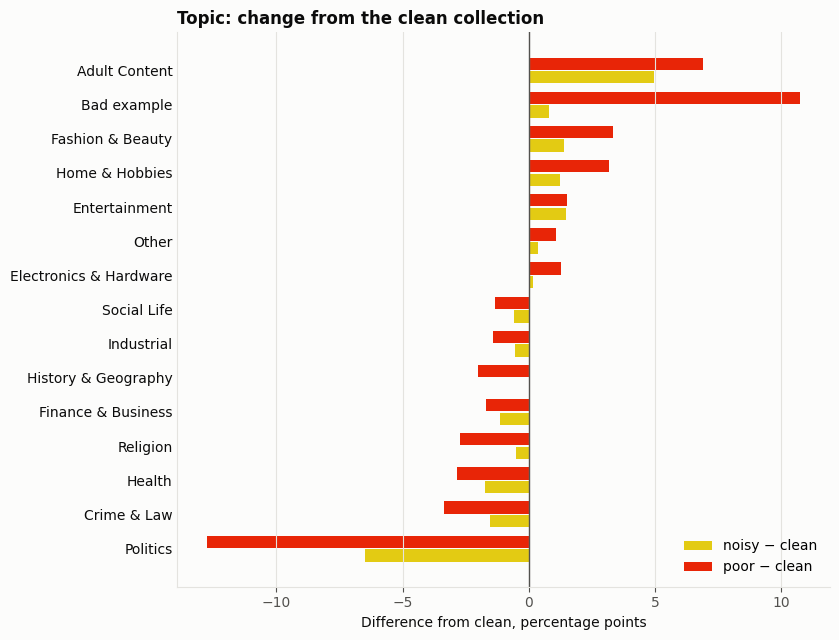

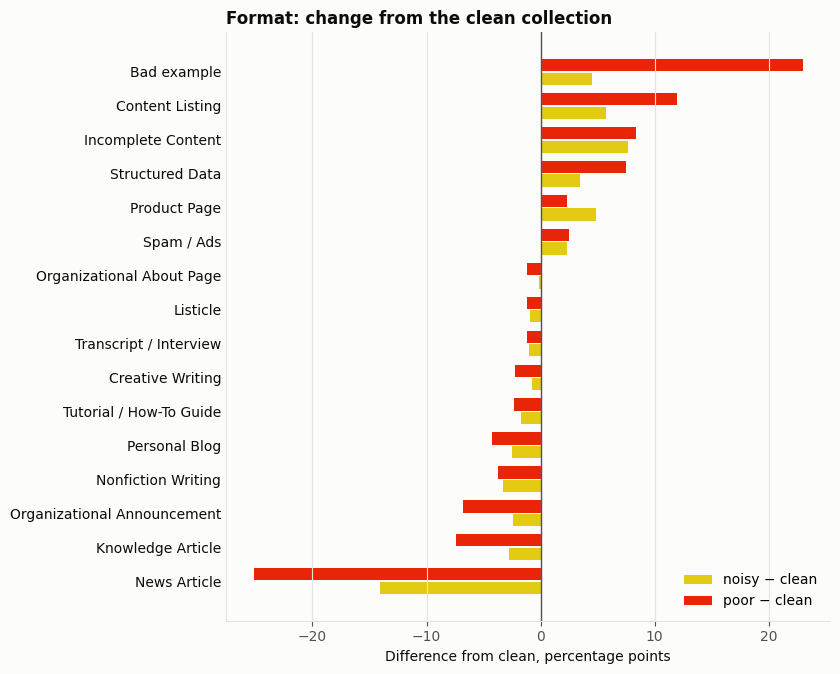

In [57]:
def plot_change_from_clean(table: pd.DataFrame, label_type: str, min_change: float = 1.0) -> None:
    share = table["share"]
    others = [quality for quality in share.columns if quality != "clean_random"]
    if "clean_random" not in share.columns or not others:
        print("Needs clean and at least one other collection")
        return
    change = share[others].sub(share["clean_random"], axis=0)
    change = change[change.abs().max(axis=1) >= min_change]
    change = change.loc[change.max(axis=1).add(change.min(axis=1)).sort_values().index]
    fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(change) + 1.4))
    y = np.arange(len(change))
    height = 0.8 / len(others)
    for i, quality in enumerate(others):
        ax.barh(y + (i - (len(others) - 1) / 2) * height, change[quality], height=height * 0.9,
                color=QUALITY_COLORS[quality], label=f"{quality.removesuffix('_random')} − clean")
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(y, change.index)
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Difference from clean, percentage points")
    ax.set_title(f"{label_type.capitalize()}: change from the clean collection", loc="left")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


plot_change_from_clean(topic_all, "topic")
plot_change_from_clean(format_all, "format")

## 4. Languages that stand out

For each collection and label type separately:

1. The **reference** is the mean distribution over the collection's languages.
2. Each language's distance from it is the **Jensen-Shannon divergence** (JSD) in bits,
   explained below.
3. A language is **flagged** when its divergence is more than `OUTLIER_MAD` median
   absolute deviations (MAD) above the median language. Median and MAD are used instead
   of mean and standard deviation so that the outliers themselves don't hide each other.

**What the Jensen-Shannon divergence measures.** For two label distributions $P$ and $Q$,
with $M = \tfrac{1}{2}(P + Q)$ their midpoint,

$$\mathrm{JS}(P, Q) = \tfrac{1}{2}\,\mathrm{KL}(P \,\|\, M) + \tfrac{1}{2}\,\mathrm{KL}(Q \,\|\, M),
\qquad \mathrm{KL}(P \,\|\, M) = \sum_i p_i \log_2 \frac{p_i}{m_i}.$$

It is 0 bits when the distributions are the same and 1 bit when they have no label in
common. One way to read it: pick $P$ or $Q$ by a fair coin flip, draw a label from the
one picked, and show only the label. The JSD is how many bits that label reveals about
which distribution it came from. Labels that are much more likely in one distribution
than in the other give it away.

Unlike the Kullback-Leibler divergence on its own, the JSD is symmetric and stays
finite when one distribution gives a label almost no probability, because both are
compared with their midpoint. It also weighs relative changes: a rare label going from
0.5% to 10% counts for more than a common one going from 20% to 29.5%.

Typical languages are not at 0, because languages really do differ: on 5 November 2026,
the median topic JSD was 0.07 bits for clean and 0.04 for poor, and Tok Pisin clean
(Religion +68 points) was at 0.43. Sampling noise from reading 3,000 documents adds
only about 0.002 bits.

`outliers` has one row per language, with its divergence, its score in MADs, and the
three labels it has most above and below the reference (in percentage points).

In [58]:
def js_bits(p: np.ndarray, q: np.ndarray) -> float:
    # Jensen-Shannon divergence of two probability vectors, in bits.
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        mask = a > 0
        return float(np.sum(a[mask] * np.log2(a[mask] / b[mask])))

    return (kl(p, m) + kl(q, m)) / 2


def describe(deviation: pd.Series, sign: int, count: int = 3, minimum: float = 3.0) -> str:
    picked = (sign * deviation).sort_values(ascending=False).head(count)
    return ", ".join(f"{label} {deviation[label]:+.0f}" for label, value in picked.items() if value >= minimum)


outlier_rows, deviations = [], {}
for (quality, label_type), group in shares.groupby(["quality", "label_type"]):
    wide = group.pivot(index="language", columns="label", values="share")[LABEL_ORDER[label_type]]
    reference = wide.mean()
    divergence = wide.apply(lambda row: js_bits(row.to_numpy(), reference.to_numpy()), axis=1)
    median = divergence.median()
    mad = (divergence - median).abs().median()
    for language, value in divergence.items():
        deviation = wide.loc[language] - reference
        deviations[quality, label_type, language] = deviation
        outlier_rows.append({
            "quality": quality, "label_type": label_type, "language": language, "js_bits": value,
            "score_mad": (value - median) / mad if mad > 0 else 0.0,
            "above_reference": describe(deviation, +1), "below_reference": describe(deviation, -1),
        })
outliers = pd.DataFrame(outlier_rows).merge(files_df, on=["quality", "label_type", "language"])
outliers["flagged"] = outliers["score_mad"] > OUTLIER_MAD
flagged = outliers[outliers["flagged"]].sort_values(["label_type", "quality", "score_mad"], ascending=[True, True, False])
print(f"{len(flagged)} flagged (language, collection, label type) combinations")

62 flagged (language, collection, label type) combinations


### Chart: how far each language is from the rest

One row per collection; each dot is a language. Grey dots are typical languages, coloured
dots are flagged and named where there is room (all flagged languages are in the
table below the charts). A collection whose dots sit further left is more alike across
languages.

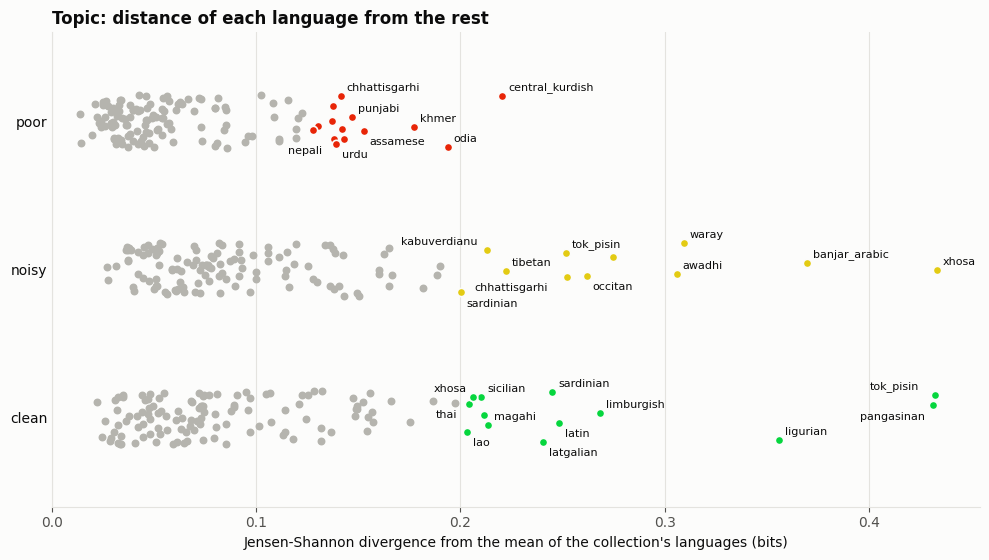

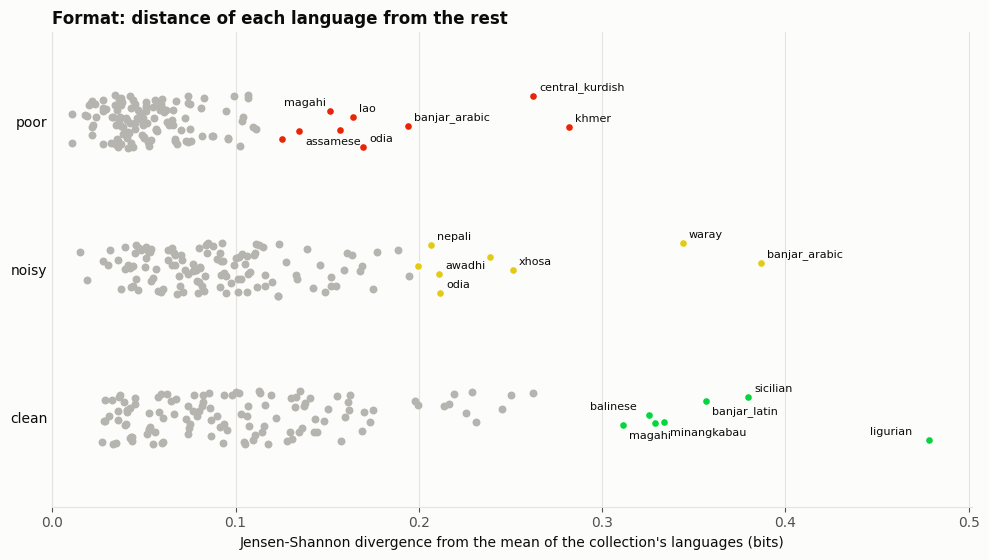

In [59]:
def plot_divergence(label_type: str) -> None:
    data = outliers[outliers["label_type"] == label_type]
    present = [quality for quality in QUALITIES if quality in set(data["quality"])]
    fig, ax = plt.subplots(figsize=(10, 1.5 * len(present) + 1.2))
    rng = np.random.default_rng(0)  # fixed jitter, so reruns look the same
    names = []
    for row, quality in enumerate(present):
        part = data[data["quality"] == quality]
        jitter = rng.uniform(-0.18, 0.18, len(part))
        typical = ~part["flagged"].to_numpy()
        ax.scatter(part["js_bits"][typical], row + jitter[typical], s=22, color=NEUTRAL, zorder=2)
        ax.scatter(part["js_bits"][~typical], row + jitter[~typical], s=36, color=QUALITY_COLORS[quality],
                   edgecolor=SURFACE, linewidth=1.2, zorder=3)
        names += [(x, y, language, score) for x, y, language, score, flag in
                  zip(part["js_bits"], row + jitter, part["language"], part["score_mad"], part["flagged"]) if flag]
    ax.set_yticks(range(len(present)), [quality.removesuffix("_random") for quality in present])
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(-0.6, len(present) - 0.4)
    ax.set_xlim(left=0)
    ax.set_xlabel("Jensen-Shannon divergence from the mean of the collection's languages (bits)")
    ax.set_title(f"{label_type.capitalize()}: distance of each language from the rest", loc="left")
    plt.tight_layout()
    annotate_without_overlap(ax, [(x, y, language) for x, y, language, _ in sorted(names, key=lambda n: -n[3])])
    plt.show()


for label_type in LABEL_TYPES:
    plot_divergence(label_type)

### The flagged languages

One row per flagged language, collection and label type. The columns:

- `score_mad`: how far the language's JSD is above the median language of its collection
  and label type, in MADs: (JSD − median JSD) / MAD. The MAD is the median of all the
  languages' distances from the median JSD, a spread measure that a few extreme
  languages can't inflate. A score of 0 is a typical language; flagged languages are
  above `OUTLIER_MAD` (4). The table is sorted by this score within each collection.
- `above_reference`: the (up to) three labels the language has most above the reference,
  with the difference in percentage points. `Religion +68` means Religion's share is
  68 points higher than the mean of the collection's languages, e.g. 74% against 6%.
  Only differences of at least 3 points are listed, so the cell can hold fewer than
  three labels, or none.
- `below_reference`: the same for the labels the language has most below the
  reference, with negative differences.
- `n`: documents read; `median_chars`: median text length in characters.
- `distinct_domains`: how many different website domains the documents come from.
- `top_domain`, `top_domain_share`: the most common domain and its share of the
  documents (%); `top5_domain_share`: the share of the five most common domains together.

In [60]:
columns = ["label_type", "quality", "language", "score_mad", "above_reference", "below_reference",
           "n", "median_chars", "distinct_domains", "top_domain", "top_domain_share", "top5_domain_share"]
display(flagged[columns].round({"score_mad": 1, "top_domain_share": 0, "top5_domain_share": 0}).reset_index(drop=True))

,label_type,quality,language,score_mad,above_reference,below_reference,n,median_chars,distinct_domains,top_domain,top_domain_share,top5_domain_share
0,format,clean_random,ligurian,9.0,"Creative Writing +42, Knowledge Article +28","News Article -29, Product Page -9, Organizational Announcement -8",3000,1236,140,lij.wikisource.org,40.0,83.0
1,format,clean_random,sicilian,6.7,"Knowledge Article +38, Creative Writing +24","News Article -28, Product Page -8, Organizational Announcement -7",3000,1238,642,scn.wikipedia.org,49.0,56.0
2,format,clean_random,banjar_latin,6.1,"Knowledge Article +36, Creative Writing +24","News Article -26, Product Page -9, Organizational Announcement -8",3000,1663,372,bjn.wikipedia.org,37.0,62.0
3,format,clean_random,minangkabau,5.6,"Knowledge Article +33, Creative Writing +17, Content Listing +4","News Article -28, Product Page -9, Organizational Announcement -8",3000,1904,570,min.wikipedia.org,37.0,51.0
4,format,clean_random,latin,5.5,"Bad example +29, Spam / Ads +6, Product Page +5","News Article -28, Organizational Announcement -7, Personal Blog -4",3000,1238,2255,la.wikipedia.org,3.0,6.0
5,format,clean_random,balinese,5.4,"Knowledge Article +33, Creative Writing +15, Structured Data +7","News Article -26, Product Page -9, Content Listing -7",3000,1728,327,ban.wikipedia.org,37.0,65.0
6,format,clean_random,magahi,5.1,"Creative Writing +26, News Article +24, Nonfiction Writing +3","Product Page -9, Content Listing -9, Organizational Announcement -8",524,1072,20,khabarlahariya.org,60.0,96.0
7,format,noisy_random,banjar_arabic,11.0,"Spam / Ads +60, Personal Blog +3","Product Page -14, Content Listing -13, News Article -7",2762,199,367,pornxxxhub.com,27.0,63.0
8,format,noisy_random,waray,9.4,"Knowledge Article +50, Other +5","Product Page -14, News Article -12, Content Listing -7",3000,264,227,war.wikipedia.org,49.0,76.0
9,format,noisy_random,xhosa,6.0,"Product Page +31, Content Listing +21","News Article -15, Incomplete Content -7, Knowledge Article -5",3000,1785,720,xh.airbnb.com,65.0,69.0


### Chart: which labels make them different

A heatmap of the flagged languages (rows) against the labels (columns): each cell is the
language's share of the label minus the collection's mean, in percentage points. Red
means more than the average language, blue less, grey about the same. Cells of at least
10 points carry their value. Labels that no flagged language differs on by 3 points or
more are left out.

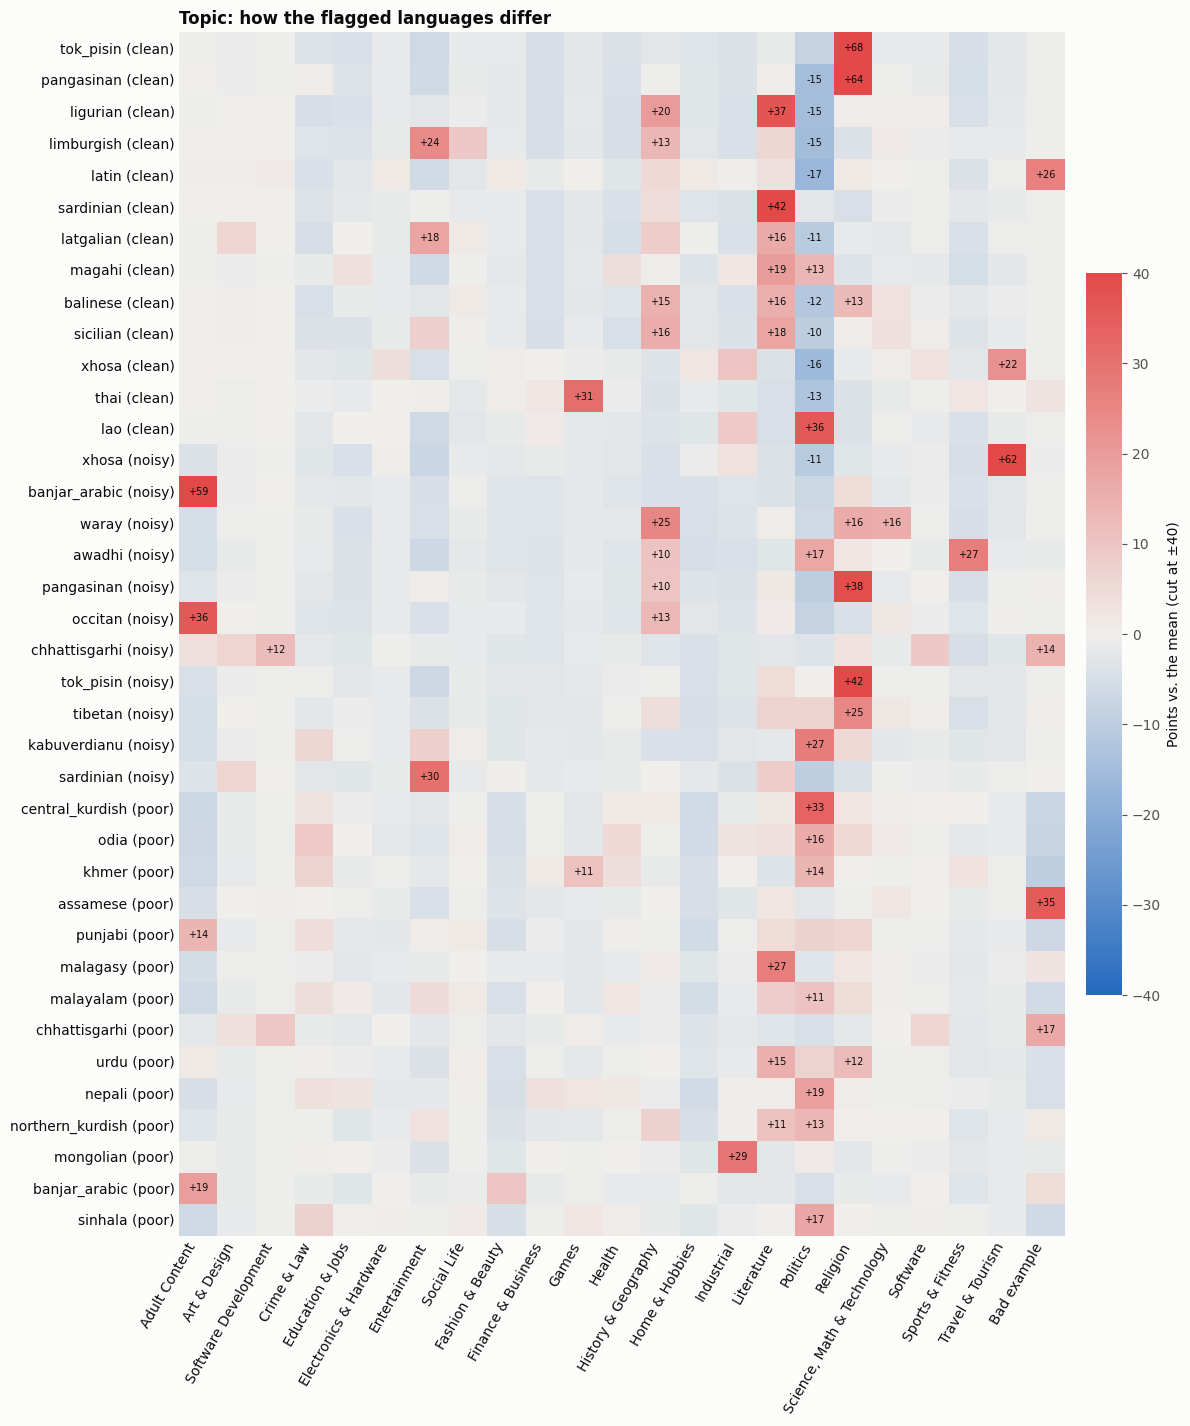

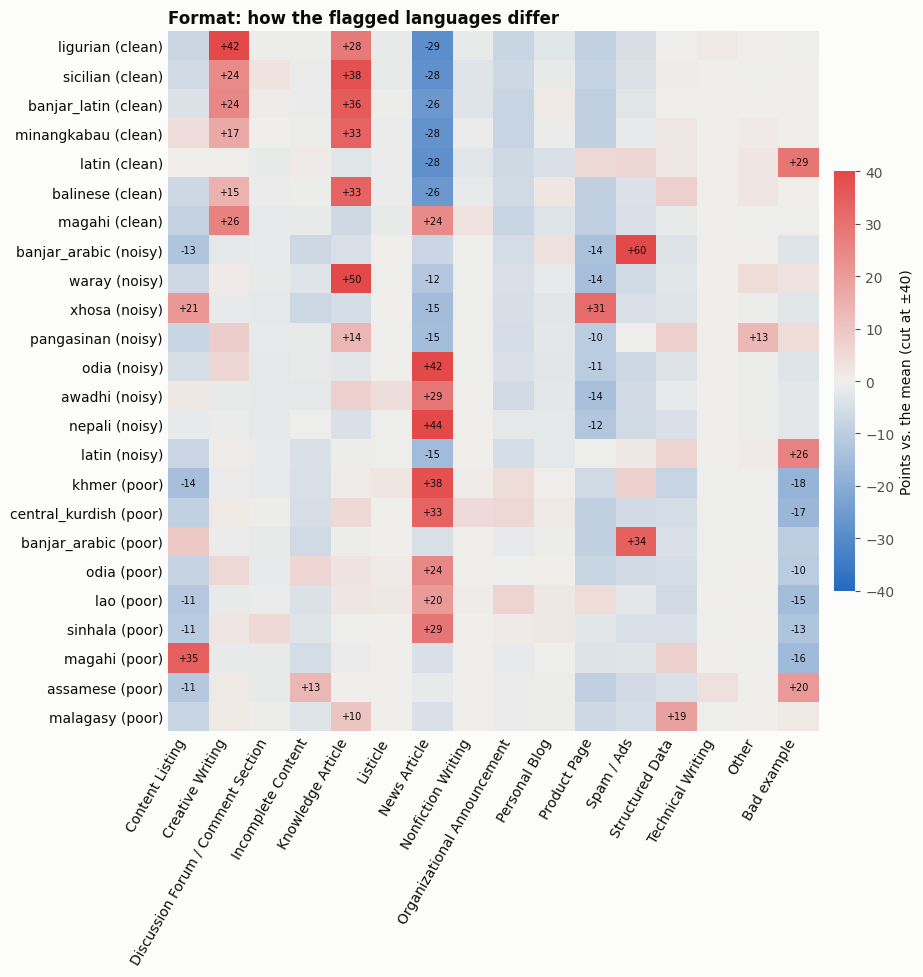

In [61]:
def plot_deviation_heatmap(label_type: str, limit: float = 40.0) -> None:
    rows = flagged[flagged["label_type"] == label_type]
    if rows.empty:
        print(f"No flagged languages for {label_type}")
        return
    matrix = pd.DataFrame(
        [deviations[item.quality, label_type, item.language] for item in rows.itertuples()],
        index=[f"{item.language} ({item.quality.removesuffix('_random')})" for item in rows.itertuples()],
    )
    matrix = matrix.loc[:, matrix.abs().max() >= 3]
    fig, ax = plt.subplots(figsize=(0.42 * matrix.shape[1] + 3, 0.32 * len(matrix) + 2.2))
    image = ax.imshow(matrix.clip(-limit, limit), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
    for (i, j), value in np.ndenumerate(matrix.to_numpy()):
        if abs(value) >= 10:
            ax.text(j, i, f"{value:+.0f}", ha="center", va="center", fontsize=7, color=TEXT)
    ax.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(matrix)), matrix.index)
    ax.tick_params(colors=TEXT, length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    bar = fig.colorbar(image, ax=ax, shrink=0.6, pad=0.02)
    bar.set_label(f"Points vs. the mean (cut at ±{limit:.0f})")
    bar.outline.set_visible(False)
    ax.set_title(f"{label_type.capitalize()}: how the flagged languages differ", loc="left")
    plt.tight_layout()
    plt.show()


for label_type in LABEL_TYPES:
    plot_deviation_heatmap(label_type)

## 5. Are a few websites behind it?

A language whose sample comes largely from a few websites gets the labels of those
websites. This chart puts each language's distance from the rest (y) against the share
of its documents that come from its five most common domains together (x): several
sites of one kind, such as Bible sites, count together. Flagged languages with at least
30% from their top five domains are named where there is room; their domains are in the
table after the charts.

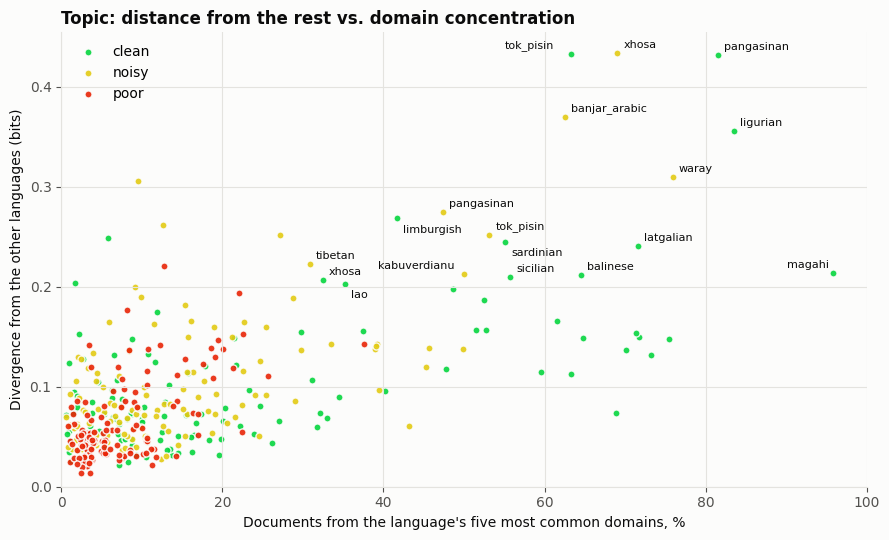

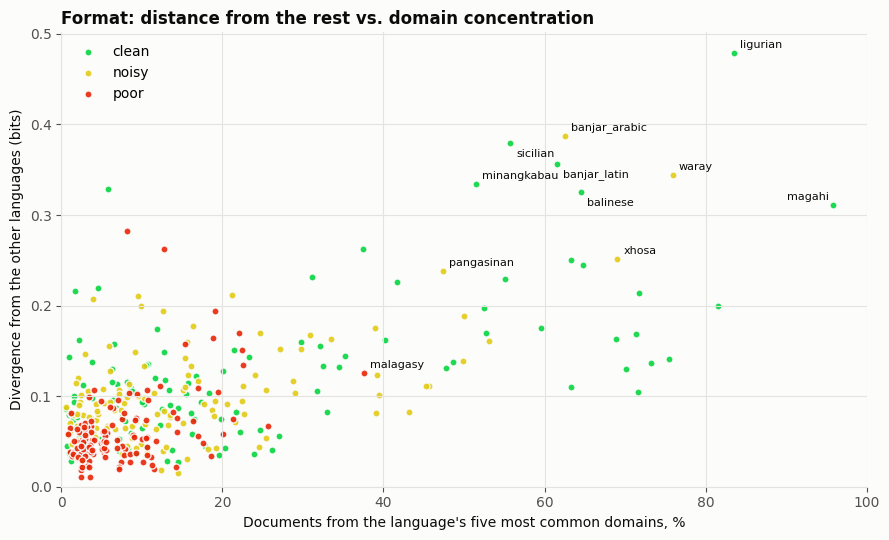

In [62]:
def plot_domain_concentration(label_type: str, min_share: float = 30.0) -> None:
    data = outliers[outliers["label_type"] == label_type]
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for quality in QUALITIES:
        part = data[data["quality"] == quality]
        if part.empty:
            continue
        ax.scatter(part["top5_domain_share"], part["js_bits"], s=26, color=QUALITY_COLORS[quality],
                   edgecolor=SURFACE, linewidth=1, alpha=0.9, label=quality.removesuffix("_random"))
    named = data[data["flagged"] & (data["top5_domain_share"] >= min_share)].sort_values("js_bits", ascending=False)
    ax.set_xlim(0, 100)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Documents from the language's five most common domains, %")
    ax.set_ylabel("Divergence from the other languages (bits)")
    ax.set_title(f"{label_type.capitalize()}: distance from the rest vs. domain concentration", loc="left")
    ax.legend(loc="upper left")
    plt.tight_layout()
    annotate_without_overlap(ax, list(zip(named["top5_domain_share"], named["js_bits"], named["language"])))
    plt.show()


for label_type in LABEL_TYPES:
    plot_domain_concentration(label_type)

The most common domains of each flagged language (the topic files; the format files hold
the same documents):

In [63]:
domain_rows = []
for item in flagged[flagged["label_type"] == "topic"].itertuples():
    summary = cache["files"][f"{item.quality}/topic/{item.language}.jsonl"]
    top = ", ".join(f"{domain} {100 * count / summary['n']:.0f}%" for domain, count in summary["top_domains"][:5])
    domain_rows.append({"quality": item.quality, "language": item.language,
                        "distinct_domains": summary["distinct_domains"], "top_domains": top})
display(pd.DataFrame(domain_rows))

,quality,language,distinct_domains,top_domains
0,clean_random,tok_pisin,194,"bible.is 21%, jw.org 16%, ebible.org 12%, pngbibleresources.org 7%, globalrecordings.net 7%"
1,clean_random,pangasinan,95,"jw.org 56%, bomboradyo.com 8%, bible.is 7%, pag.wikipedia.org 6%, wikisource.org 5%"
2,clean_random,ligurian,140,"lij.wikisource.org 40%, lij.wikipedia.org 35%, lij.m.wikipedia.org 4%, wikisource.org 2%, ostafi.net 2%"
3,clean_random,limburgish,700,"li.wikipedia.org 23%, limburgslied.nl 9%, li.wikinews.org 5%, veldeke.net 2%, nds-nl.wikipedia.org 2%"
4,clean_random,latin,2255,"la.wikipedia.org 3%, la.wikisource.org 1%, books.google.pl 1%, latin.it 1%, la.m.wikipedia.org 1%"
5,clean_random,sardinian,367,"ditzionariu.sardegnacultura.it 24%, ditzionariu.nor-web.eu 10%, salimbasarda.net 7%, sc.wikipedia.org 7%, ilminuto.i..."
6,clean_random,latgalian,178,"lakuga.lv 53%, lgsc.lv 6%, valoda.ailab.lv 6%, lr1.lsm.lv 3%, ltg.wikipedia.org 3%"
7,clean_random,magahi,20,"khabarlahariya.org 60%, magahi-sahitya.blogspot.com 31%, magahi-sahitya.blogspot.in 2%, gotquestions.org 2%, incubat..."
8,clean_random,balinese,327,"ban.wikipedia.org 37%, dictionary.basabali.org 16%, suarasakingbali.com 6%, alkitab.mobi 3%, ban.wikisource.org 3%"
9,clean_random,sicilian,642,"scn.wikipedia.org 49%, scn.m.wikipedia.org 2%, sihd.it 2%, antoniogarrisiopere.it 1%, assarca.com 1%"


## 6. Example documents

For each flagged language, the first document whose top label is the label the language
has most above the reference, cut to 300 characters. Read these to tell the causes
apart: a few websites, text in another language than its tag, or a real feature of the
language's web.

In [64]:
for item in flagged.itertuples():
    deviation = deviations[item.quality, item.label_type, item.language]
    label = deviation.idxmax()
    short_name = {full: short for short, full in LABELS[item.label_type].items()}[label]
    summary = cache["files"][f"{item.quality}/{item.label_type}/{item.language}.jsonl"]
    example = summary["examples"].get(short_name)
    print(f"── {item.language} ({item.quality}, {item.label_type}): {label} {deviation[label]:+.0f} points")
    if example is None:
        print("   (no document with this top label)")
        continue
    print(f"   {example['url']}")
    print("   " + " ".join(example["text"].split())[:300])

── ligurian (clean_random, format): Creative Writing +42 points
   http://www.polpomario.com/2021/04/20/nitam-o-pescou-e-a-doce-derfinn-a-riscia/
   Due parolle do traduttô. Quande son stæto incaregòu da l’Editô de fâ a traduzion in zeneize da föa do Ciuffardi, mì no conosceivo questo Autore e me son dito: «Proprio a mì m’àn çercòu pe a traduzion de ‘na föa ch’a vegne da-a Baia de Föe?» E pensavo a-o premio Andersen; perché questa pe mì e l’è pr
── sicilian (clean_random, format): Knowledge Article +38 points
   https://scn.wikipedia.org/wiki/Muvumentu_Hazzm
   Muvumentu Hazzm Lu Muvumentu Hazzm ('n àrabbu: حركة حزم, Harakat Hazzm, chi significa Muvumentu di firmezza) è n'allianza di mudirati ribbelli siriani sècunnu na dichiarazziuni di iddi. Carattiristichi[cancia | cancia la surgenti] A lu gruppu è statu furnitu lu BGM-71 TOW nu missili anticarru da na 
── banjar_latin (clean_random, format): Knowledge Article +36 points
   https://bjn.wikipedia.org/wiki/Sungai_Brunai
   Sungai Brun

## 7. Findings (5 November 2026)

What the analysis showed when it was written, with 3,000 documents per file. Clean was
complete; noisy had 128 languages for topic and 125 for format; poor had only topic, and
only for languages 0–39 of `data/qwen_label_languages.txt`. Rerun the notebook as more
results come in; the numbers above replace these.

**By data quality (topic):** clean is news-like and poor is junk and commerce, with noisy
in between. Politics falls from 18% (clean) to 12% (noisy) and 5% (poor). Bad example rises
from 1% to 2% and 13%, and Adult Content from 0.4% to 5% and 9%. Fashion & Beauty,
Home & Hobbies and Electronics & Hardware also rise in poor; Health, Crime & Law, Religion
and History & Geography fall. The picture is the same on the 39 languages that all three
collections have. Poor varies least between languages.

**By data quality (format, clean vs. noisy):** News Article falls from 30% to 16%;
Knowledge Article, Nonfiction Writing, Personal Blog and Tutorial also fall. Incomplete
Content (2% → 10%), Structured Data (1% → 5%), Bad example (0.5% → 5%), Product Page and
Content Listing rise.

**Languages that stand out**, by cause:

- *A few websites dominate:* Tok Pisin and Pangasinan (Religion 70–74%: bible.is, jw.org);
  Xhosa (Travel & Tourism; two thirds of noisy is xh.airbnb.com listings); Waray noisy
  (Wikipedia stubs); Ligurian, Sicilian, Lombard, Venetian, Banjar Latin, Minangkabau and
  Balinese clean (Wikipedia and Wikisource: Literature and Knowledge Article up, News down);
  Latgalian clean (53% from lakuga.lv); Limburgish clean (Wikipedia and a song-lyrics site:
  Entertainment up); Lao clean (Lao editions of Vietnamese state media: Politics +36);
  Magahi clean (only 524 documents from 20 domains, 60% khabarlahariya.org).
- *Not really the language:* Banjar Arabic noisy (Arabic-script porn spam); Latin (about a
  quarter "lorem ipsum" placeholders and WordPress default posts, labelled Bad example);
  Awadhi noisy (mostly Hindi news); Occitan noisy (Adult Content, apparently French
  escort-spam lists of place names); Assamese poor (half Bad example: code and scraps, with a
  median length of 52 characters).
- *A real feature of the language's web:* Thai clean (lottery tips on news sites, labelled
  Games); Central Kurdish poor (news, more Politics than other poor languages); Odia,
  Nepali, Assamese and Kabuverdianu noisy (more News Article).

The format outliers are mostly the same languages as the topic outliers.

For training, the domain-dominated languages would teach the classifier that the language
implies the label: a per-domain cap in `create_datasets.py` would counter that. The
languages whose text isn't in the language give misleading per-language test scores.